# Dinámica del mercado en el tiempo

El scraper nacional corrió varias veces seguidas (una corrida completa cada 3 o 4 días en julio de 2026) y
`data/raw/` conserva **todas** las capturas, no solo la última. Eso permite seguir un mismo anuncio entre
corridas y medir tres cosas que una sola foto del mercado no muestra:

1. **Rotación**: qué fracción de los anuncios desaparece o aparece entre corridas.
2. **Cambios de precio**: con qué frecuencia y de qué tamaño ajustan los vendedores el precio de un mismo anuncio.
3. **Deriva del nivel de precios**: si el mercado sube o baja, separando ese efecto del cambio en la mezcla de anuncios.

**Límites que conviene tener presentes**

- Son precios de **oferta**, no de cierre. Un anuncio que desaparece pudo venderse, arrendarse o retirarse, y no hay forma de distinguirlo.
- La ventana es de unas 4 semanas. Sirve para volatilidad de corto plazo y rotación, no para tendencias ni estacionalidad.
- Una corrida no ve necesariamente todos los anuncios publicados (la paginación del sitio cambia mientras se recorre).
  Por eso se mide por separado cuánta de la "rotación" aparente es cobertura incompleta.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
COLUMNS = {"listing_id", "price_cop", "area_m2", "department", "department_real", "listing_created_at", "scraped_at"}

# Mismos rangos de dominio que src/pipelines/clean_data.py
MIN_PRICE_COP, MAX_PRICE_COP = 50_000_000, 10_000_000_000
MIN_AREA_M2, MAX_AREA_M2 = 15, 1_000

## 1. Carga de las capturas

Se leen solo las corridas completas (`run<fecha>` en el nombre del archivo); el backfill de "resto de Colombia" es
una captura aparte y se excluye. Dentro de una misma corrida un anuncio puede aparecer varias veces (el sitio
reordena resultados mientras se pagina), así que se conserva la observación más reciente por corrida.

In [2]:
frames = []
for path in sorted((ROOT / "data" / "raw").glob("*.csv")):
    match = re.search(r"run(\d{8}T\d{6})", path.name)
    if not match:
        continue
    part = pd.read_csv(path, encoding="utf-8-sig", usecols=lambda c: c in COLUMNS, low_memory=False)
    part["run"] = match.group(1)
    frames.append(part)
raw = pd.concat(frames, ignore_index=True)

raw["scraped_at"] = pd.to_datetime(raw["scraped_at"], utc=True, errors="coerce")
raw["listing_created_at"] = pd.to_datetime(raw["listing_created_at"], utc=True, errors="coerce")
raw["department_final"] = raw["department_real"].fillna(raw["department"])

raw = raw[
    raw["price_cop"].between(MIN_PRICE_COP, MAX_PRICE_COP) & raw["area_m2"].between(MIN_AREA_M2, MAX_AREA_M2)
]
snap = raw.sort_values("scraped_at").drop_duplicates(["run", "listing_id"], keep="last")

print(f"Filas crudas válidas: {len(raw):,}")
print(f"Tras conservar una observación por anuncio y corrida: {len(snap):,}")
print(f"Anuncios únicos: {snap['listing_id'].nunique():,}")
print(f"Repeticiones dentro de una misma corrida: {1 - len(snap) / len(raw):.1%} de las filas")

runs = sorted(snap["run"].unique())
run_date = {r: pd.to_datetime(r, format="%Y%m%dT%H%M%S", utc=True) for r in runs}
coverage = pd.DataFrame({
    "anuncios": snap.groupby("run")["listing_id"].nunique(),
    "precio_mediano_m2": (snap["price_cop"] / snap["area_m2"]).groupby(snap["run"]).median(),
})
coverage.index = [run_date[r].strftime("%Y-%m-%d") for r in coverage.index]
coverage.round(0).astype(int)

Filas crudas válidas: 1,251,075
Tras conservar una observación por anuncio y corrida: 377,698
Anuncios únicos: 82,736
Repeticiones dentro de una misma corrida: 69.8% de las filas


,anuncios,precio_mediano_m2
2026-07-03,46479,5500000
2026-07-07,47245,5483871
2026-07-11,47642,5500000
2026-07-14,46836,5500000
2026-07-17,46822,5520417
2026-07-20,46816,5514362
2026-07-24,48667,5510204
2026-07-27,47191,5559147


## 2. Rotación: ¿cuánto cambia el conjunto de anuncios?

Para cada par de corridas consecutivas se calcula qué fracción de los anuncios de la corrida anterior **persiste**
y qué fracción de la nueva corrida es **nueva**.

     desde      hasta  persisten_%  nuevos_%
2026-07-03 2026-07-07         72.5      28.7
2026-07-07 2026-07-11         71.9      28.7
2026-07-11 2026-07-14         72.1      26.6
2026-07-14 2026-07-17         71.2      28.8
2026-07-17 2026-07-20         72.4      27.6
2026-07-20 2026-07-24         73.3      29.5
2026-07-24 2026-07-27         71.9      25.8


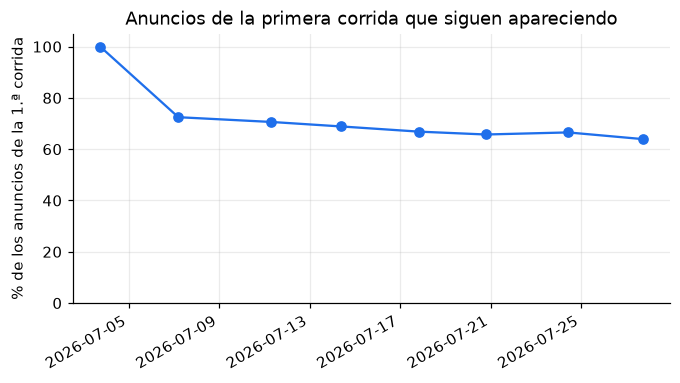

In [3]:
sets = {r: set(snap.loc[snap["run"] == r, "listing_id"]) for r in runs}

rows = []
for a, b in zip(runs, runs[1:]):
    rows.append({
        "desde": run_date[a].strftime("%Y-%m-%d"),
        "hasta": run_date[b].strftime("%Y-%m-%d"),
        "persisten_%": 100 * len(sets[a] & sets[b]) / len(sets[a]),
        "nuevos_%": 100 * len(sets[b] - sets[a]) / len(sets[b]),
    })
rotacion = pd.DataFrame(rows)
print(rotacion.round(1).to_string(index=False))

first = sets[runs[0]]
supervivencia = [100 * len(first & sets[r]) / len(first) for r in runs]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot([run_date[r] for r in runs], supervivencia, marker="o", color="#1f6feb")
ax.set_ylim(0, 105)
ax.set_ylabel("% de los anuncios de la 1.ª corrida")
ax.set_title("Anuncios de la primera corrida que siguen apareciendo")
fig.autofmt_xdate()
plt.show()

Si los anuncios se vendieran o retiraran a un ritmo constante, la curva caería de forma geométrica y llegaría a
valores muy bajos en 4 semanas. Aquí la caída más fuerte ocurre en el **primer** paso y luego casi se estabiliza,
lo que sugiere que una parte de las ausencias no es rotación real sino cobertura incompleta. Dos pruebas lo
separan:

- **Reapariciones**: un anuncio retirado de verdad rara vez vuelve. Si de los que faltan en una corrida muchos
  reaparecen en la siguiente, el scraper simplemente no los vio.
- **Entradas reales**: de los anuncios "nuevos" en una corrida, cuántos fueron **creados** después de la corrida
  anterior (`listing_created_at`). Los demás ya existían y se habían escapado.

In [4]:
reaparecen = []
for a, b, c in zip(runs, runs[1:], runs[2:]):
    ausentes = sets[a] - sets[b]
    reaparecen.append(100 * len(ausentes & sets[c]) / len(ausentes))
print(f"De los anuncios ausentes en una corrida, reaparecen en la siguiente: {np.mean(reaparecen):.1f}% (promedio de {len(reaparecen)} tripletas)")

created = snap.drop_duplicates("listing_id").set_index("listing_id")["listing_created_at"]
nuevos_reales = []
for a, b in zip(runs, runs[1:]):
    nuevos = sets[b] - sets[a]
    creados_despues = (created.reindex(list(nuevos)) > run_date[a]).mean()
    nuevos_reales.append(100 * creados_despues)
print(f"De los anuncios 'nuevos' en una corrida, creados después de la corrida anterior: {np.mean(nuevos_reales):.1f}% (promedio)")

# Cota superior de desapariciones reales: anuncios de la 1.ª corrida que no se ven en NINGUNA corrida posterior
despues = set().union(*(sets[r] for r in runs[1:]))
no_vuelven = 100 * len(first - despues) / len(first)
print(f"Anuncios de la 1.ª corrida que no aparecen en ninguna de las {len(runs) - 1} corridas siguientes: {no_vuelven:.1f}% (cota superior de retiros reales)")

De los anuncios ausentes en una corrida, reaparecen en la siguiente: 46.7% (promedio de 6 tripletas)
De los anuncios 'nuevos' en una corrida, creados después de la corrida anterior: 5.3% (promedio)
Anuncios de la 1.ª corrida que no aparecen en ninguna de las 7 corridas siguientes: 4.0% (cota superior de retiros reales)


## 3. Cambios de precio de un mismo anuncio

Se compara el precio de cada anuncio entre corridas consecutivas en las que aparece.

Comparaciones de un mismo anuncio entre corridas consecutivas: 238,597
Con cambio de precio: 1,709 (0.7%)
  Bajas: 58.3% de los cambios | Subidas: 41.7%
  Tamaño mediano del cambio (en valor absoluto): 3.6%
  Percentiles del cambio (p10 / p50 / p90): -6.9% / -1.1% / +9.1%


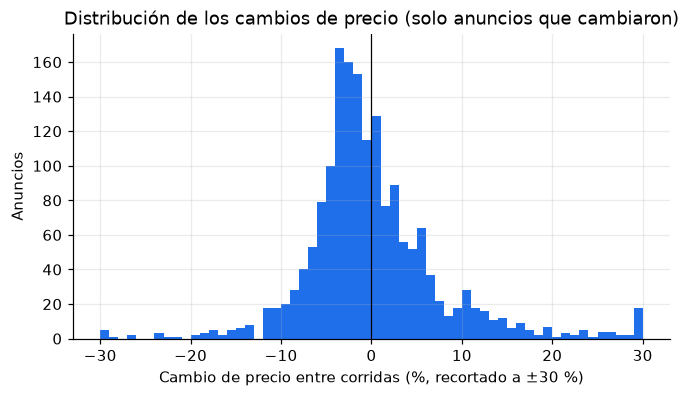

In [5]:
price = snap.pivot(index="listing_id", columns="run", values="price_cop")
dept = snap.drop_duplicates("listing_id").set_index("listing_id")["department_final"]

pairs = []
for a, b in zip(runs, runs[1:]):
    both = price[[a, b]].dropna()
    pairs.append(pd.DataFrame({"cambio": both[b] / both[a] - 1, "hasta": run_date[b]}).reset_index())
cambios = pd.concat(pairs, ignore_index=True)
cambios["departamento"] = cambios["listing_id"].map(dept)

hubo = cambios[cambios["cambio"].abs() > 1e-9]
print(f"Comparaciones de un mismo anuncio entre corridas consecutivas: {len(cambios):,}")
print(f"Con cambio de precio: {len(hubo):,} ({len(hubo) / len(cambios):.1%})")
print(f"  Bajas: {(hubo['cambio'] < 0).mean():.1%} de los cambios | Subidas: {(hubo['cambio'] > 0).mean():.1%}")
print(f"  Tamaño mediano del cambio (en valor absoluto): {hubo['cambio'].abs().median():.1%}")
print("  Percentiles del cambio (p10 / p50 / p90): " + " / ".join(f"{hubo['cambio'].quantile(q):+.1%}" for q in (0.1, 0.5, 0.9)))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(hubo["cambio"].clip(-0.3, 0.3) * 100, bins=60, color="#1f6feb")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Cambio de precio entre corridas (%, recortado a ±30 %)")
ax.set_ylabel("Anuncios")
ax.set_title("Distribución de los cambios de precio (solo anuncios que cambiaron)")
plt.show()

### Por departamento

Solo los 8 departamentos con más comparaciones, para que los porcentajes tengan base suficiente.

In [6]:
top = cambios["departamento"].value_counts().head(8).index
por_dep = (
    cambios[cambios["departamento"].isin(top)]
    .assign(cambio_precio=lambda d: d["cambio"].abs() > 1e-9)
    .groupby("departamento")
    .agg(comparaciones=("cambio", "size"), con_cambio_pct=("cambio_precio", lambda s: 100 * s.mean()))
)
por_dep["cambio_mediano_pct"] = (
    hubo[hubo["departamento"].isin(top)].groupby("departamento")["cambio"].median() * 100
)
por_dep.sort_values("comparaciones", ascending=False).round(2)

,comparaciones,con_cambio_pct,cambio_mediano_pct
departamento,,,
Resto de Colombia,35413,1.36,-1.11
Valle del Cauca,24536,0.54,-2.78
Antioquia,20737,0.50,-1.37
Cundinamarca,20645,0.87,-1.78
Risaralda,18211,0.31,1.43
Atlántico,16113,0.40,-0.00
Bolívar,14461,0.28,-0.38
"Bogotá, d.c.",14453,1.56,-0.24


## 4. ¿Sube o baja el nivel de precios?

Comparar la mediana de precio por m² entre corridas mezcla dos efectos: que los precios cambien y que **cambie la
mezcla** de anuncios (si entran más anuncios caros, la mediana sube sin que ningún precio haya subido). Por eso
se muestran tres series, todas con base 100 en la primera corrida:

- **Mediana de precio por m²** de todos los anuncios de cada corrida (incluye el efecto de mezcla).
- **Índice encadenado**: variación media del logaritmo del precio (recortada a ±30 %) de los anuncios presentes en dos
  corridas consecutivas, acumulada. Mide solo cambios de precio de anuncios que persisten.
- **Panel balanceado**: solo los anuncios presentes en **todas** las corridas.

Anuncios presentes en las 8 corridas: 13,010


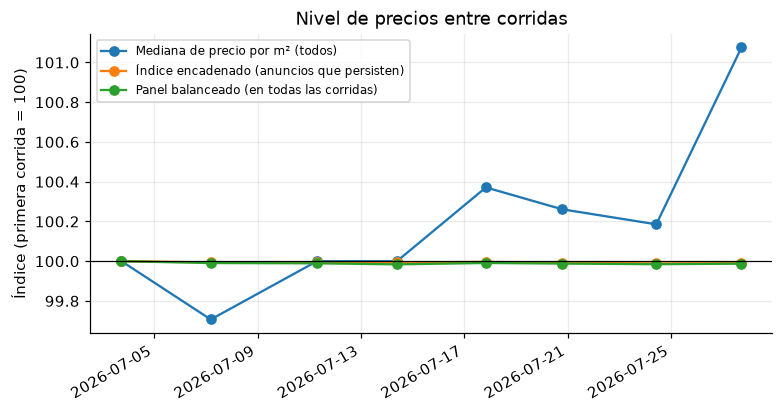

,Mediana de precio por m² (todos),Índice encadenado (anuncios que persisten),Panel balanceado (en todas las corridas)
2026-07-03,100.00,100.00,100.00
2026-07-07,99.71,99.99,99.99
2026-07-11,100.00,99.99,99.99
2026-07-14,100.00,99.99,99.98
2026-07-17,100.37,100.00,99.99
2026-07-20,100.26,99.99,99.99
2026-07-24,100.19,99.99,99.98
2026-07-27,101.08,99.99,99.99


In [7]:
recorte = lambda s: s.clip(-0.3, 0.3)  # cambios extremos suelen ser errores de captura; no se usan percentiles porque casi todos los cambios son 0

nivel = {"Mediana de precio por m² (todos)": [], "Índice encadenado (anuncios que persisten)": [1.0], "Panel balanceado (en todas las corridas)": []}

ppm2 = (snap["price_cop"] / snap["area_m2"]).groupby(snap["run"]).median()
nivel["Mediana de precio por m² (todos)"] = list(ppm2 / ppm2.iloc[0])

nivel["Índice encadenado (anuncios que persisten)"] = [1.0]
for a, b in zip(runs, runs[1:]):
    both = price[[a, b]].dropna()
    paso = recorte(np.log(both[b] / both[a])).mean()
    nivel["Índice encadenado (anuncios que persisten)"].append(nivel["Índice encadenado (anuncios que persisten)"][-1] * np.exp(paso))

balanced = price.dropna()
print(f"Anuncios presentes en las {len(runs)} corridas: {len(balanced):,}")
base = balanced[runs[0]]
nivel["Panel balanceado (en todas las corridas)"] = [np.exp(recorte(np.log(balanced[r] / base)).mean()) for r in runs]

fig, ax = plt.subplots(figsize=(8, 4))
for etiqueta, serie in nivel.items():
    ax.plot([run_date[r] for r in runs], np.array(serie) * 100, marker="o", label=etiqueta)
ax.axhline(100, color="black", lw=0.8)
ax.set_ylabel("Índice (primera corrida = 100)")
ax.set_title("Nivel de precios entre corridas")
ax.legend(fontsize=8)
fig.autofmt_xdate()
plt.show()

pd.DataFrame(nivel, index=[run_date[r].strftime("%Y-%m-%d") for r in runs]).mul(100).round(2)

## 5. Conclusiones

Resultados con las 8 corridas de julio de 2026 (3 al 27 de julio). Las cifras salen de las celdas de arriba y pueden cambiar si se agregan corridas.

**La "rotación" aparente es sobre todo cobertura incompleta, no mercado.**
Entre corridas consecutivas solo persiste cerca del 72 % de los anuncios, lo que parece una rotación enorme. Pero
el 46,7 % de los anuncios que faltan en una corrida reaparecen en la siguiente, y solo el 5,3 % de los anuncios
"nuevos" fueron creados después de la corrida anterior: el resto ya existía y el scraper no lo había visto.
Una sola corrida no es un censo del mercado.

**Los retiros reales en 4 semanas son pocos.**
Como máximo el 4,0 % de los anuncios de la primera corrida no vuelve a aparecer en ninguna de las 7 siguientes
(cota superior, porque también incluye anuncios que el scraper simplemente no vio). En esta ventana el inventario
es casi estable y los anuncios "muertos" acumulados son una fracción pequeña.

**Los vendedores casi no ajustan el precio en el corto plazo, y cuando lo hacen suele ser a la baja.**
Solo el 0,7 % de las comparaciones entre corridas consecutivas muestra un cambio de precio. Entre los que cambian,
el 58 % son bajas, el cambio mediano en valor absoluto es del 3,6 % y el 80 % central va de -6,9 % a +9,1 %.

**No hay deriva del nivel de precios en la ventana.**
Con los mismos anuncios (índice encadenado y panel balanceado) el nivel queda en 99,98 a 100,00, es decir, plano.
La mediana de precio por m² de todos los anuncios sube un 1,1 % entre la primera y la última corrida, pero eso
refleja un cambio de mezcla de anuncios y no un alza de precios.

**Qué implica y qué falta**
- Para medir inventario (cuántos anuncios hay) conviene usar la unión de varias corridas y no una sola.
- Cuatro semanas no bastan para ver tendencias ni estacionalidad. Una corrida nueva, meses después de estas,
  dará la primera lectura útil de deriva de precios y de retiros reales.
- Límite de esta lectura: `listing_created_at` se tomó como fecha de creación del anuncio; si el sitio la
  reinicia al republicar, la proporción de anuncios realmente nuevos estaría subestimada.